<a href="https://colab.research.google.com/github/mahathirumalathi97-web/FOOD-DELIVERY-ANALYSIS/blob/main/Food_Delivery_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Food Delivery Business Analysis

In [1]:
import pandas as pd
import numpy as np

In [2]:
customer = pd.read_csv("/content/customers.csv")
delivery = pd.read_csv("/content/delivery.csv")
order = pd.read_csv("/content/orders.csv")
restaurant = pd.read_csv("/content/restaurants.csv")

In [3]:
customer.head(5)

,customer_id,name,city,signup_date
0,CUST001,Customer 1,Chennai,2025-05-07
1,CUST002,Customer 2,Chennai,2025-10-15
2,CUST003,Customer 3,Bangalore,2025-10-03
3,CUST004,Customer 4,Mumbai,2025-05-15
4,CUST005,Customer 5,Mumbai,2025-10-27


In [4]:
delivery.head(5)

,order_id,delivery_agent_id,delivery_time_mins,distance_km
0,ORD0002,AGNT013,41,11.4
1,ORD0003,AGNT046,27,5.2
2,ORD0004,AGNT049,62,8.5
3,ORD0005,AGNT043,58,11.5
4,ORD0006,AGNT035,35,11.9


In [5]:
order.head(5)

,order_id,customer_id,restaurant_id,order_time,order_value,payment_mode,order_status
0,ORD0001,CUST070,REST028,2026-01-16 23:20:00,210.02,COD,Cancelled
1,ORD0002,CUST065,REST001,2026-05-16 05:03:00,1158.82,Credit Card,Delivered
2,ORD0003,CUST009,REST005,2026-06-02 02:43:00,1054.91,UPI,Delivered
3,ORD0004,CUST073,REST004,2026-03-05 18:38:00,191.73,COD,Delivered
4,ORD0005,CUST085,REST027,2026-05-30 18:33:00,482.19,Credit Card,Delivered


In [6]:
restaurant.head(5)

,restaurant_id,name,cuisine_type,city,rating
0,REST001,Restaurant 1,South Indian,Hyderabad,3.8
1,REST002,Restaurant 2,North Indian,Hyderabad,4.8
2,REST003,Restaurant 3,North Indian,Delhi,4.1
3,REST004,Restaurant 4,South Indian,Mumbai,4.7
4,REST005,Restaurant 5,Biryani,Delhi,4.3


In [7]:
# Shapes
print(f"customer -", customer.shape)
print(f"delivery - ", delivery.shape)
print(f"order - ", order.shape)
print(f"restuarant - ", restaurant.shape)

customer - (100, 4)
delivery -  (810, 4)
order -  (1010, 7)
restuarant -  (30, 5)


In [8]:
# dtypes
print(f"customer -", customer.dtypes)
print(f"delivery - ", delivery.dtypes)
print(f"order - ", order.dtypes)
print(f"restuarant - ", restaurant.dtypes)

customer - customer_id    object
name           object
city           object
signup_date    object
dtype: object
delivery -  order_id               object
delivery_agent_id      object
delivery_time_mins      int64
distance_km           float64
dtype: object
order -  order_id          object
customer_id       object
restaurant_id     object
order_time        object
order_value      float64
payment_mode      object
order_status      object
dtype: object
restuarant -  restaurant_id     object
name              object
cuisine_type      object
city              object
rating           float64
dtype: object


In [9]:
# Change the dtypes
customer['signup_date'] = pd.to_datetime(customer['signup_date'])
order['order_time'] = pd.to_datetime(order['order_time'])

In [10]:
# column names
print("customer column -", customer.columns)
print("delivery column -", delivery.columns)
print("order column -", order.columns)
print("restaurant column -", restaurant.columns)

customer column - Index(['customer_id', 'name', 'city', 'signup_date'], dtype='object')
delivery column - Index(['order_id', 'delivery_agent_id', 'delivery_time_mins', 'distance_km'], dtype='object')
order column - Index(['order_id', 'customer_id', 'restaurant_id', 'order_time', 'order_value',
       'payment_mode', 'order_status'],
      dtype='object')
restaurant column - Index(['restaurant_id', 'name', 'cuisine_type', 'city', 'rating'], dtype='object')


In [11]:
# Null values
print("customer null values -", customer.isnull().sum())
print("delivery null values -", delivery.isnull().sum())
print("order null values -", order.isnull().sum())
print("restaurant null values -", restaurant.isnull().sum())

customer null values - customer_id    0
name           0
city           0
signup_date    0
dtype: int64
delivery null values - order_id              0
delivery_agent_id     0
delivery_time_mins    0
distance_km           0
dtype: int64
order null values - order_id           0
customer_id        0
restaurant_id      0
order_time         0
order_value        0
payment_mode     168
order_status       0
dtype: int64
restaurant null values - restaurant_id    0
name             0
cuisine_type     0
city             0
rating           0
dtype: int64


In [12]:
# null values replace with fillna
mode_payment = order["payment_mode"].mode()[0]
order["payment_mode"] = order["payment_mode"].fillna(mode_payment)

In [13]:
# Check duplicate values
print("customer null values -", customer.duplicated().sum())
print("delivery null values -", delivery.duplicated().sum())
print("order null values -", order.duplicated().sum())
print("restaurant null values -", restaurant.duplicated().sum())

customer null values - 0
delivery null values - 0
order null values - 10
restaurant null values - 0


In [14]:
# drop the duplicate
order = order.drop_duplicates()

In [15]:
# Merge all tables into a single Master DataFrame
df = order.merge(customer, on='customer_id', how='left', suffixes=('', '_cust'))
df = df.merge(restaurant, on='restaurant_id', how='left', suffixes=('', '_rest'))
df = df.merge(delivery, on='order_id', how='left')

In [16]:
# Delivery delay flag (Assuming > 45 mins is delayed)
delivery['is_delayed'] = delivery['delivery_time_mins'].apply(lambda x: 'Yes' if x > 45 else 'No')

In [17]:
 # Feature Engineering (Extra useful columns for analysis)
order['order_hour'] = order['order_time'].dt.hour
order['order_day'] = order['order_time'].dt.day_name()
order['order_month'] = order['order_time'].dt.to_period('M')

In [18]:
# Save the cleaned datasets
order.to_csv('cleaned_orders.csv', index=False)
delivery.to_csv('cleaned_delivery.csv', index=False)
df.to_csv('master_food_delivery.csv', index=False)

In [19]:
print("customer", customer.shape)
print("delivery", delivery.shape)
print("order", order.shape)
print("restaurant", restaurant.shape)
print("df", df.shape)

customer (100, 4)
delivery (810, 5)
order (1000, 10)
restaurant (30, 5)
df (1000, 17)


# Python EDA & RFM

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Load the master dataset
df = pd.read_csv('master_food_delivery.csv')

# Convert order_time to datetime format
df['order_time'] = pd.to_datetime(df['order_time'])
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (1000, 17)


,order_id,customer_id,restaurant_id,order_time,order_value,payment_mode,order_status,name,city,signup_date,name_rest,cuisine_type,city_rest,rating,delivery_agent_id,delivery_time_mins,distance_km
0,ORD0001,CUST070,REST028,2026-01-16 23:20:00,210.02,COD,Cancelled,Customer 70,Mumbai,2025-01-30,Restaurant 28,Burgers & Pizza,Mumbai,3.9,NaN,NaN,NaN
1,ORD0002,CUST065,REST001,2026-05-16 05:03:00,1158.82,Credit Card,Delivered,Customer 65,Delhi,2025-01-10,Restaurant 1,South Indian,Hyderabad,3.8,AGNT013,41.0,11.4
2,ORD0003,CUST009,REST005,2026-06-02 02:43:00,1054.91,UPI,Delivered,Customer 9,Chennai,2025-07-05,Restaurant 5,Biryani,Delhi,4.3,AGNT046,27.0,5.2
3,ORD0004,CUST073,REST004,2026-03-05 18:38:00,191.73,COD,Delivered,Customer 73,Hyderabad,2025-02-10,Restaurant 4,South Indian,Mumbai,4.7,AGNT049,62.0,8.5
4,ORD0005,CUST085,REST027,2026-05-30 18:33:00,482.19,Credit Card,Delivered,Customer 85,Mumbai,2025-09-28,Restaurant 27,North Indian,Delhi,3.7,AGNT043,58.0,11.5


In [21]:
#  Trend Visualizations (Monthly Revenue & Peak Order Hours)

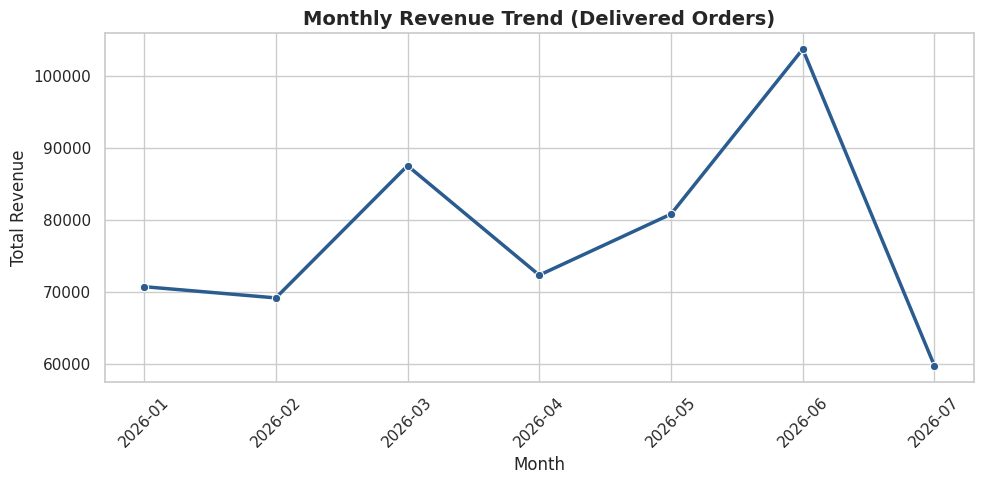

/tmp/ipykernel_860/3599472135.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hourly_orders, x='order_hour', y='order_id', palette='viridis')


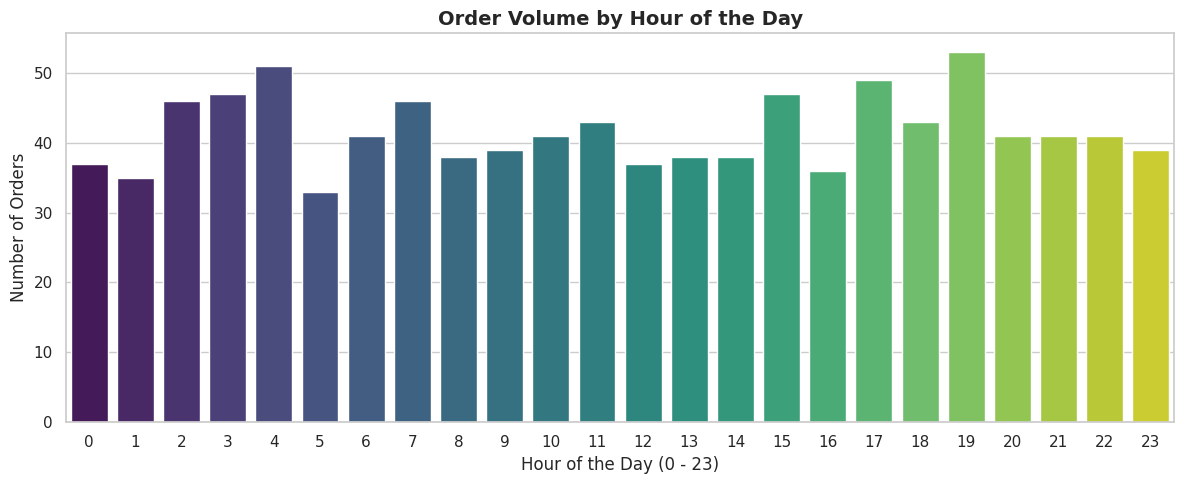

<Axes: xlabel='order_hour', ylabel='order_id'>

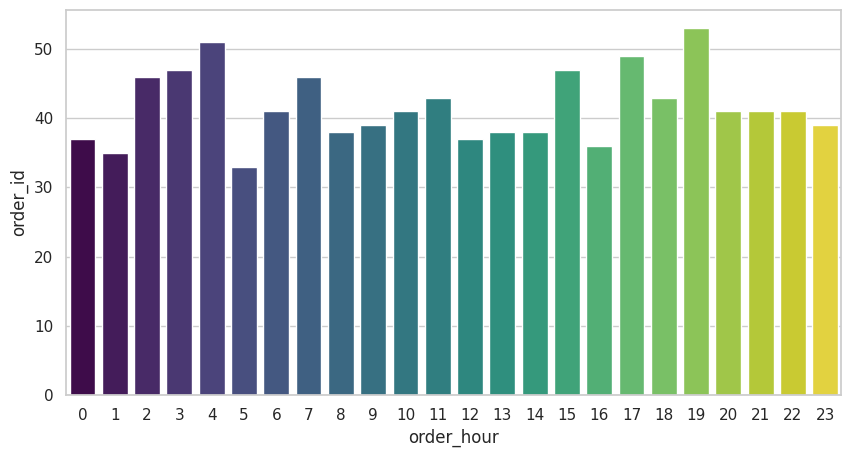

In [22]:
# Filter only Delivered orders for revenue analysis
delivered_df = df[df['order_status'] == 'Delivered'].copy()

# Create missing temporal features on the DataFrames
delivered_df['order_month'] = delivered_df['order_time'].dt.to_period('M')
df['order_hour'] = df['order_time'].dt.hour

# Convert Period to string for easier plotting with seaborn
delivered_df['order_month'] = delivered_df['order_month'].astype(str)

# 1. Monthly Revenue Trend
monthly_rev = delivered_df.groupby('order_month')['order_value'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_rev, x='order_month', y='order_value', marker='o', linewidth=2.5, color='#2b5c8f')
plt.title('Monthly Revenue Trend (Delivered Orders)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Order Volume by Hour of the Day
hourly_orders = df.groupby('order_hour')['order_id'].count().reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=hourly_orders, x='order_hour', y='order_id', palette='viridis')
plt.title('Order Volume by Hour of the Day', fontsize=14, fontweight='bold')
plt.xlabel('Hour of the Day (0 - 23)', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.tight_layout()
plt.show()

sns.barplot(data=hourly_orders, x='order_hour', y='order_id', hue='order_hour', palette='viridis', legend=False)

In [ ]:
# Correlation Analysis (Delivery Time, Distance & Ratings)

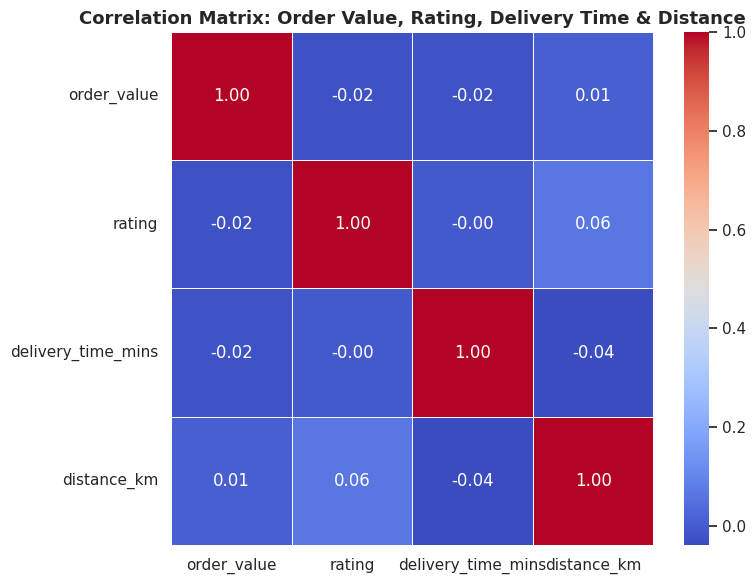

/tmp/ipykernel_860/3588484210.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=delivered_df, x='rating', y='delivery_time_mins', palette='Set2')


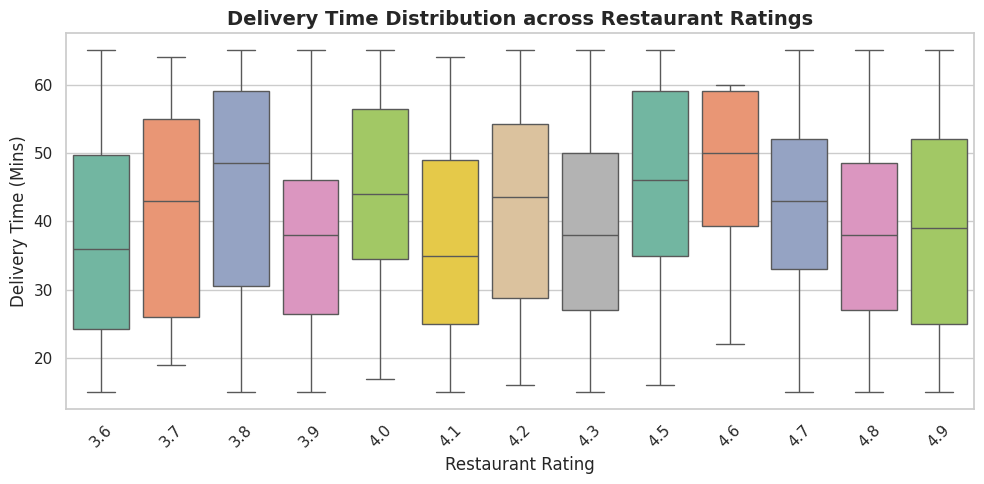

In [23]:
# Select numerical columns for correlation
corr_cols = ['order_value', 'rating', 'delivery_time_mins', 'distance_km']
corr_matrix = delivered_df[corr_cols].corr()

# 1. Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix: Order Value, Rating, Delivery Time & Distance', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Delivery Time vs. Restaurant Rating (Boxplot)
plt.figure(figsize=(10, 5))
sns.boxplot(data=delivered_df, x='rating', y='delivery_time_mins', palette='Set2')
plt.title('Delivery Time Distribution across Restaurant Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Restaurant Rating', fontsize=12)
plt.ylabel('Delivery Time (Mins)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# Customer Segmentation using RFM Analysis

        Customer_Segment  customer_id  Recency  Frequency  Monetary
0  At Risk / Hibernating           14    69.43       3.93   2481.48
1              Champions           28     9.18      11.64   8145.91
2        Loyal Customers           19    18.74       9.00   5950.34
3    Potential / Regular           39    23.74       6.62   4307.60


/tmp/ipykernel_860/1376693076.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x='Customer_Segment', order=rfm['Customer_Segment'].value_counts().index, palette='magma')


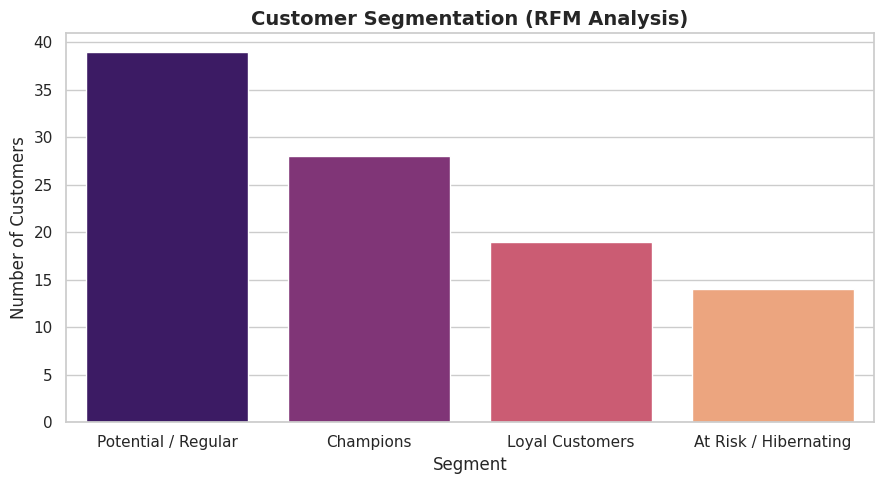

In [24]:
# Set reference date as 1 day after the latest order in the dataset
snapshot_date = delivered_df['order_time'].max() + pd.Timedelta(days=1)

# Calculate Recency, Frequency, Monetary for each customer
rfm = delivered_df.groupby('customer_id').agg({
    'order_time': lambda x: (snapshot_date - x.max()).days, # Recency
    'order_id': 'count',                                    # Frequency
    'order_value': 'sum'                                    # Monetary
}).reset_index()

rfm.columns = ['customer_id', 'Recency', 'Frequency', 'Monetary']

# Assign scores from 1 to 4 (4 is best)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=[1, 2, 3, 4])

# Calculate overall RFM Score
rfm['RFM_Score'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

# Create Customer Segments
def segment_customer(score):
    if score >= 10:
        return 'Champions'
    elif score >= 8:
        return 'Loyal Customers'
    elif score >= 5:
        return 'Potential / Regular'
    else:
        return 'At Risk / Hibernating'

rfm['Customer_Segment'] = rfm['RFM_Score'].apply(segment_customer)

# View Segment Summary
segment_summary = rfm.groupby('Customer_Segment').agg({
    'customer_id': 'count',
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2).reset_index()

print(segment_summary)

# Plot Customer Segments
plt.figure(figsize=(9, 5))
sns.countplot(data=rfm, x='Customer_Segment', order=rfm['Customer_Segment'].value_counts().index, palette='magma')
plt.title('Customer Segmentation (RFM Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('Segment', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.tight_layout()
plt.show()

# Save RFM results to CSV (Optional: You can use this in Power BI too!)
rfm.to_csv('customer_rfm_segments.csv', index=False)
